# Probability Calibration and Final Validation

Objectives:
1. Compare original and calibrated churn models.
2. Evaluate calibration using Brier score and log loss.
3. Select a model using validation data.
4. Evaluate the selected approach on untouched test accounts.
5. Generate reproducible predictions for Snowflake.

The test set must not influence model selection.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    brier_score_loss, log_loss,
    roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

df = pd.read_csv(
    "../data/raw/Case_Study_2_CLV_Predictive_Analytics.csv"
)

TARGET = "churn_event_next_12m"

FEATURES = [
    "current_capacity_tb",
    "utilization_rate_pct",
    "utilization_above_100_flag",
    "expansion_potential_signal"
]

labeled_df = df[df[TARGET].notna()].copy()
labeled_df["utilization_above_100_flag"] = (
    labeled_df["utilization_rate_pct"] > 1.0
).astype(int)

split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
tr_idx, temp_idx = next(
    split1.split(labeled_df, groups=labeled_df["account_id"])
)

train_df = labeled_df.iloc[tr_idx].copy()
temp_df = labeled_df.iloc[temp_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)
v_idx, te_idx = next(
    split2.split(temp_df, groups=temp_df["account_id"])
)

val_df = temp_df.iloc[v_idx].copy()
test_df = temp_df.iloc[te_idx].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET].astype(int)
X_val = val_df[FEATURES]
y_val = val_df[TARGET].astype(int)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert set(train_df.account_id).isdisjoint(val_df.account_id)
assert set(train_df.account_id).isdisjoint(test_df.account_id)
assert set(val_df.account_id).isdisjoint(test_df.account_id)

Train: 1328
Validation: 280
Test: 276


In [7]:
def make_preprocessor():
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), [
            "current_capacity_tb",
            "utilization_rate_pct",
            "utilization_above_100_flag"
        ]),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), ["expansion_potential_signal"])
    ])

def make_rf():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=3,
            min_samples_leaf=20,
            random_state=42,
            n_jobs=-1
        ))
    ])

def make_xgb():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", XGBClassifier(
            n_estimators=150,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=10,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])

In [8]:
rf = make_rf()
xgb = make_xgb()

rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)

rf_prob = rf.predict_proba(X_val)[:, 1]
xgb_prob = xgb.predict_proba(X_val)[:, 1]

print("Uncalibrated models trained successfully.")

Uncalibrated models trained successfully.


In [9]:
group_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

calibration_folds = list(
    group_cv.split(
        X_train,
        y_train,
        groups=train_df["account_id"]
    )
)

# Verify account separation in every fold
groups = train_df["account_id"].to_numpy()

for fold, (fit_idx, cal_idx) in enumerate(calibration_folds, 1):
    assert set(groups[fit_idx]).isdisjoint(set(groups[cal_idx]))
    print(f"Fold {fold}: account separation verified")

Fold 1: account separation verified
Fold 2: account separation verified
Fold 3: account separation verified


In [11]:
rf_sigmoid = CalibratedClassifierCV(
    estimator=make_rf(),
    method="sigmoid",
    cv=calibration_folds,
    ensemble=True
)

rf_isotonic = CalibratedClassifierCV(
    estimator=make_rf(),
    method="isotonic",
    cv=calibration_folds,
    ensemble=True
)

rf_sigmoid.fit(X_train, y_train)
rf_isotonic.fit(X_train, y_train)

rf_sig_prob = rf_sigmoid.predict_proba(X_val)[:, 1]
rf_iso_prob = rf_isotonic.predict_proba(X_val)[:, 1]

print("Random Forest calibration completed.")

Random Forest calibration completed.


In [13]:
def evaluate(name, y, p):
    return {
        "Model": name,
        "Brier": brier_score_loss(y, p),
        "Log Loss": log_loss(y, p, labels=[0, 1]),
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Mean Predicted": p.mean(),
        "Observed": y.mean()
    }

p_static = np.full(len(y_val), 0.05)
p_prevalence = np.full(len(y_val), y_train.mean())

validation_results = pd.DataFrame([
    evaluate("Static 5%", y_val, p_static),
    evaluate("Training Prevalence", y_val, p_prevalence),
    evaluate("RF Core", y_val, rf_prob),
    evaluate("XGB Core", y_val, xgb_prob),
    evaluate("RF Sigmoid", y_val, rf_sig_prob),
    evaluate("RF Isotonic", y_val, rf_iso_prob)
])

display(
    validation_results.sort_values("Brier").round(4)
)

,Model,Brier,Log Loss,ROC-AUC,PR-AUC,Mean Predicted,Observed
1,Training Prevalence,0.1397,0.4526,0.5000,0.1679,0.1611,0.1679
2,RF Core,0.1401,0.4542,0.5322,0.1917,0.1626,0.1679
4,RF Sigmoid,0.1402,0.4543,0.4581,0.1596,0.1602,0.1679
3,XGB Core,0.1402,0.4547,0.5231,0.1856,0.1603,0.1679
5,RF Isotonic,0.1408,0.4547,0.5498,0.1814,0.1622,0.1679
0,Static 5%,0.1536,0.5455,0.5000,0.1679,0.0500,0.1679


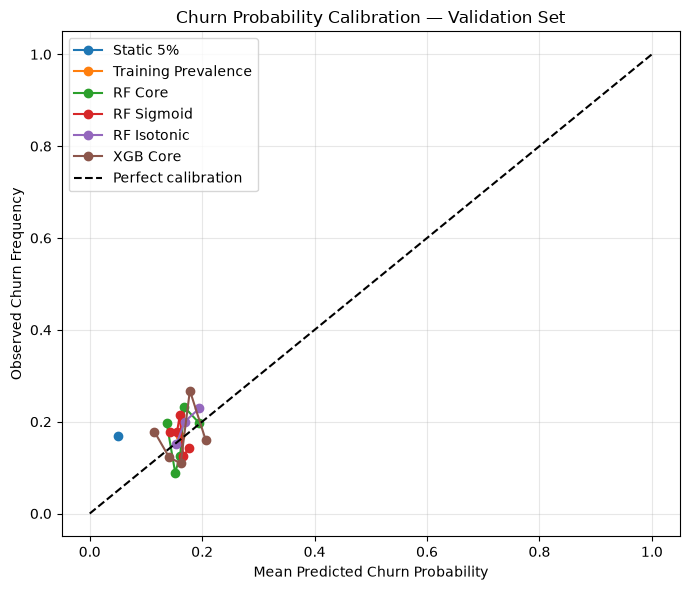

In [14]:
plt.figure(figsize=(7, 6))

models_to_plot = {
    "Static 5%": p_static,
    "Training Prevalence": p_prevalence,
    "RF Core": rf_prob,
    "RF Sigmoid": rf_sig_prob,
    "RF Isotonic": rf_iso_prob,
    "XGB Core": xgb_prob
}

for name, probabilities in models_to_plot.items():
    observed, predicted = calibration_curve(
        y_val,
        probabilities,
        n_bins=5,
        strategy="quantile"
    )
    plt.plot(predicted, observed, marker="o", label=name)

plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Observed Churn Frequency")
plt.title("Churn Probability Calibration — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
